# Vẽ minh họa hình học của điều chuẩn L1 và L2 (mục 3.2.3)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Hàm mất mát MSE có đường đồng mức dạng elip, tâm là nghiệm OLS w_ols

In [2]:
w_ols = np.array([2.0, 0.4])
H = np.array([[1.0, 0.3], [0.3, 1.2]])     # ma trận quyết định hình dạng elip
w1, w2 = np.meshgrid(np.linspace(-2, 3.5, 400), np.linspace(-2, 3, 400))
diff = np.stack([w1 - w_ols[0], w2 - w_ols[1]], axis=-1)
loss = np.einsum('...i,ij,...j->...', diff, H, diff)   # giá trị hàm mất mát trên lưới

def loss_at(points):
    """Hàm mất mát tại các điểm (mỗi hàng là một điểm [w1, w2])."""
    d = points - w_ols
    return np.einsum('ni,ij,nj->n', d, H, d)

Vẽ hình và lưu ảnh.

Nghiệm Lasso: [1. 0.]


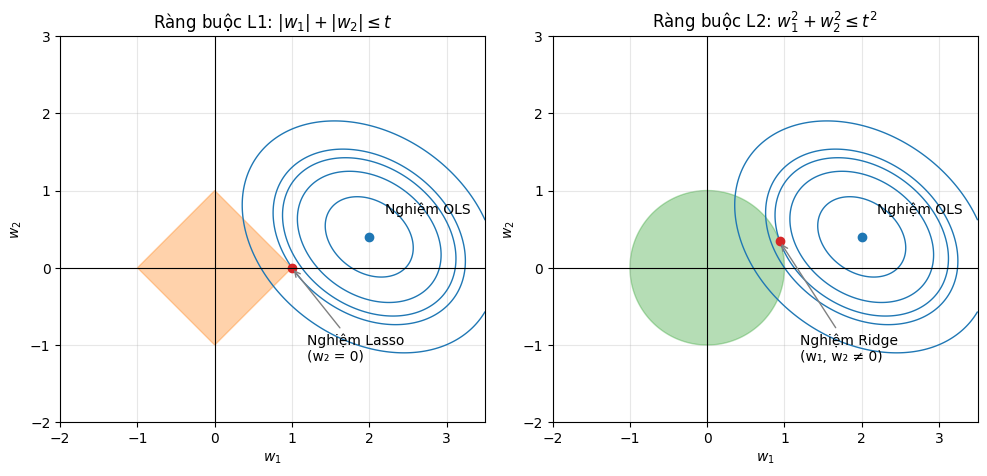

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, name in zip(axes, ["L1 (Lasso)", "L2 (Ridge)"]):
    ax.contour(w1, w2, loss, levels=[0.3, 0.8, 1.165, 1.432, 2.5], colors="#1F77B4", linewidths=1)
    ax.plot(*w_ols, 'o', color="#1F77B4")
    ax.annotate("Nghiệm OLS", w_ols, xytext=(w_ols[0] + 0.2, w_ols[1] + 0.3))
    if name.startswith("L1"):
        t = 1.0                            # bán kính miền ràng buộc |w1| + |w2| <= t
        ax.fill([t, 0, -t, 0], [0, t, 0, -t], color="#FF7F0E", alpha=0.35)
        # Lấy nhiều điểm trên biên hình thoi, chọn điểm có hàm mất mát nhỏ nhất
        s = np.linspace(0, 1, 2001)[:, None]
        border = np.concatenate([(1 - s) * [t, 0] + s * [0, t], (1 - s) * [0, t] + s * [-t, 0],
                                 (1 - s) * [-t, 0] + s * [0, -t], (1 - s) * [0, -t] + s * [t, 0]])
        best = border[np.argmin(loss_at(border))]
        print("Nghiệm Lasso:", best)
        ax.plot(*best, 'o', color="#D62728")
        ax.annotate("Nghiệm Lasso\n(w₂ = 0)", best, xytext=(1.2, -1.2),
                    arrowprops=dict(arrowstyle="->", color="gray"))
        ax.set_title(r"Ràng buộc L1: $|w_1| + |w_2| \leq t$")
    else:
        angle = np.linspace(0, 2 * np.pi, 200)
        ax.fill(np.cos(angle), np.sin(angle), color="#2CA02C", alpha=0.35)
        # Lấy các điểm trên đường tròn, chọn điểm có hàm mất mát nhỏ nhất
        border = np.stack([np.cos(angle), np.sin(angle)], axis=1)
        best = border[np.argmin(loss_at(border))]
        ax.plot(*best, 'o', color="#D62728")
        ax.annotate("Nghiệm Ridge\n(w₁, w₂ ≠ 0)", best, xytext=(1.2, -1.2),
                    arrowprops=dict(arrowstyle="->", color="gray"))
        ax.set_title(r"Ràng buộc L2: $w_1^2 + w_2^2 \leq t^2$")
    ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$")
    ax.set_aspect("equal"); ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(IMAGES / "l1_l2.png", dpi=150)